In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from glhmm import glhmm, preproc, utils, statistics, graphics

In [2]:
try:
    import google.colab
    IN_COLAB = True
    !pip install -q git+https://github.com/vidaurre/glhmm
except ImportError:
    IN_COLAB = False

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from glhmm import glhmm, preproc, utils, statistics, graphics

In [3]:
# ── User settings ─────────────────────────────────────────────────────────
# Same data as ghmm_full_EEG.ipynb: run its "Load and prepare data" cells first (with the settings you want,
# e.g. NAP_DURATION_MIN, SLEEP_STAGES), they save Y_prep / indices_prep / sessions_meta to out_dir
out_dir   = Path('C:/Users/eva/Documents/Master/ICM/Ilo/GLHMM/outputs')
MODEL_TAG = 'bandpower'  # 'bandpower' (SLEEP_STAGES = True in ghmm_full_EEG) or 'raw'
# ──────────────────────────────────────────────────────────────────────────

Y_prep = np.load(out_dir / f'Y_prep_full_eeg_{MODEL_TAG}.npy')
indices_prep = np.load(out_dir / f'indices_prep_full_eeg_{MODEL_TAG}.npy')
sessions_meta = pd.read_csv(out_dir / 'sessions_meta_full_eeg.csv')
assert len(sessions_meta) == len(indices_prep), 'sessions_meta and indices_prep come from different runs of ghmm_full_EEG'
assert np.isfinite(Y_prep).all(), 'NaN/inf in Y_prep'

print(f'Y_prep shape       : {Y_prep.shape}  (n_samples_total x n_features)')
print(f'indices_prep shape : {indices_prep.shape}  ({sessions_meta.subject.nunique()} subjects)')
print(f'Samples per session: {np.unique(np.diff(indices_prep, axis=1))}')

Y_prep shape       : (115200, 25)  (n_samples_total x n_features)
indices_prep shape : (16, 2)  (16 subjects)
Samples per session: [7200]


No preprocessing here: `Y_prep` is already preprocessed by ghmm_full_EEG.ipynb (band-power envelopes standardised within each subject when `MODEL_TAG = 'bandpower'`, `preproc.preprocess_data` when `'raw'`), so the models below are trained on exactly the data of ghmm_full_EEG. Its preprocessing log is not saved, hence `log_preproc=None`.

In [12]:
# ── Model settings ───────────────────────────────────────────────────────
COVTYPE    = 'sharedfull'  # as in ghmm_full_EEG: 'full' | 'diag' | 'shareddiag' | 'sharedfull'
MODEL_MEAN = 'state'       # as in ghmm_full_EEG (glhmm default): states differ by their mean band power
# ──────────────────────────────────────────────────────────────────────────
state_range = range(2, 7)   # K values to evaluate (2, ..., 10)
n_repeats   = 15              # independent runs per K
SAVE_DIR    = out_dir / f'choose_K_{COVTYPE}_{MODEL_TAG}'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print(f'K values    : {list(state_range)}')
print(f'Repetitions : {n_repeats}')
print(f'Results dir : {SAVE_DIR}')

K values    : [2, 3, 4, 5, 6]
Repetitions : 15
Results dir : C:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\outputs\choose_K_sharedfull_bandpower


In [13]:
# ── Training options ──────────────────────────────────────────────────────
# glhmm default cycles, as in ghmm_full_EEG
options = {
    'verbose': False,
}
# ──────────────────────────────────────────────────────────────────────────

results = utils.run_stability_training(
    Y_prep, indices_prep, state_range, n_repeats, SAVE_DIR,
    log_preproc=None,
    covtype=COVTYPE,
    model_mean=MODEL_MEAN,
    options=options,
)

Training HMM with 2 states (15 repetitions)...
  K=2  rep=1/15  FE=2939940.35
  K=2  rep=2/15  FE=2939939.29
  K=2  rep=3/15  FE=2937487.86
  K=2  rep=4/15  FE=2939939.26
  K=2  rep=5/15  FE=2937487.06
  K=2  rep=6/15  FE=2940772.83
  K=2  rep=7/15  FE=2939939.29
  K=2  rep=8/15  FE=2939939.23
  K=2  rep=9/15  FE=2937487.63
  K=2  rep=10/15  FE=2939939.23
  K=2  rep=11/15  FE=2939969.19
  K=2  rep=12/15  FE=2937487.91
  K=2  rep=13/15  FE=2940771.92
  K=2  rep=14/15  FE=2939939.36
  K=2  rep=15/15  FE=2939939.39
  K=2  105 pairwise similarities  mean=0.7867
Training HMM with 3 states (15 repetitions)...
  K=3  rep=1/15  FE=2904084.11
  K=3  rep=2/15  FE=2904063.83
  K=3  rep=3/15  FE=2904073.57
  K=3  rep=4/15  FE=2904065.14
  K=3  rep=5/15  FE=2904373.07
  K=3  rep=6/15  FE=2916157.66
  K=3  rep=7/15  FE=2904063.13
  K=3  rep=8/15  FE=2904088.40
  K=3  rep=9/15  FE=2904064.28
  K=3  rep=10/15  FE=2904063.63
  K=3  rep=11/15  FE=2904086.39
  K=3  rep=12/15  FE=2904063.20
  K=3  rep=13/

Load saved results
Run this cell instead of the training cell above if results already exist.

Case A: summary_results.pkl present -> loads directly.

Case B: Only individual hmm_K*_rep*.pkl files -> rebuilds the summary.

In [14]:
results, state_range = utils.load_stability_results(SAVE_DIR)

Loaded summary_results.pkl  (K = [2, 3, 4, 5, 6])

    K | N reps | N sim scores |   Min final FE
--------------------------------------------
   2 |     15 |          105 |     2937487.06
   3 |     15 |          105 |     2904063.13
   4 |     15 |          105 |     2877031.08
   5 |     15 |          105 |     2856430.21
   6 |     15 |          105 |     2842393.81


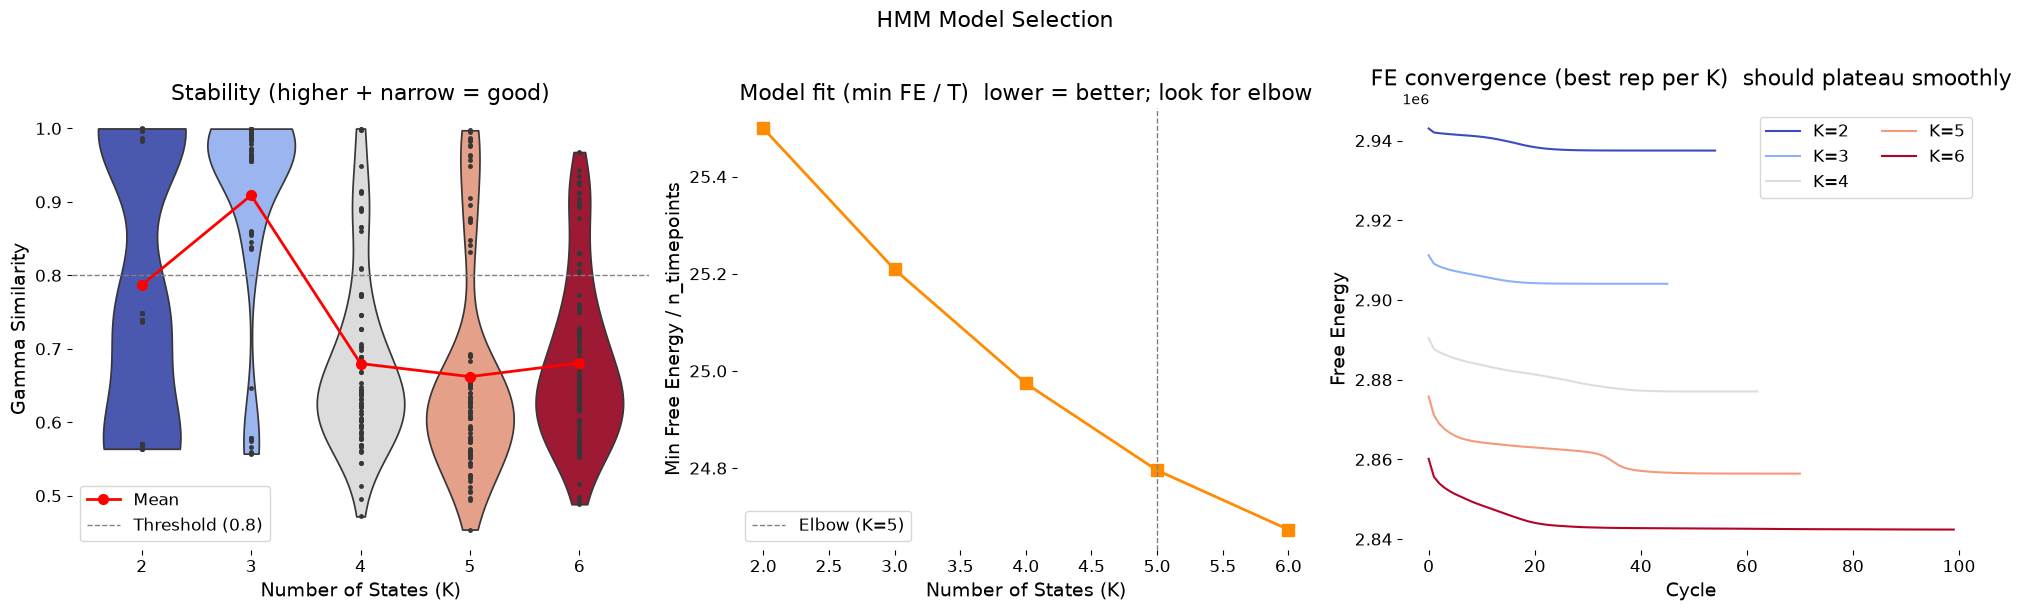

    K |  Mean Sim |  Std Sim |   Min FE/T | Converged?
----------------------------------------------------
   2 |    0.7867 |   0.1863 |      25.50 |        yes
   3 |    0.9090 |   0.1380 |      25.21 |        yes
   4 |    0.6800 |   0.1189 |      24.97 |        yes
   5 |    0.6621 |   0.1416 |      24.80 |        yes
   6 |    0.6808 |   0.1132 |      24.67 |        yes


In [15]:
avg_similarity, min_fe = graphics.plot_model_selection(
    results, Y_prep.shape[0],
    save_path=str(SAVE_DIR / 'model_selection.png'),
)